In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(os.path.join(OUTPUT_DIR, name), dpi=130, bbox_inches="tight")

print("TensorFlow version:", tf.__version__)

I0000 00:00:1795031574.972756   13912 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795031574.979323   13912 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795031577.783690   13912 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795031577.787196   13912 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0


# Section 3: Coding the convolution operation

In [2]:
import tensorflow as tf
import numpy as np

# Random seed
tf.keras.utils.set_random_seed(42)

# Convolution layer with 16 filters of size 3x3
conv = tf.keras.layers.Conv2D(
    filters=16,
    kernel_size=(3, 3),
    activation='relu',
    kernel_initializer='he_normal'
)

# Sample input image
dummy_input = tf.random.normal((1, 128, 128, 1))

# Convolution operation
output = conv(dummy_input)

# Get the weights
weights, biases = conv.get_weights()

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print("Filter weights shape:", weights.shape)
print("Bias shape:", biases.shape)

# Weights of the first filter
print("First filter:")
print(weights[:, :, 0, 0])

Input shape: (1, 128, 128, 1)
Output shape: (1, 126, 126, 16)
Filter weights shape: (3, 3, 1, 16)
Bias shape: (16,)
First filter:
[[-0.25283593  0.12861036 -0.75786656]
 [-0.21681367 -0.15182823 -0.702172  ]
 [ 0.23038778  0.76512676 -0.74278826]]


E0000 00:00:1795031578.354521   13912 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.


Additional analysis used to answer the questions:

In [3]:
np.set_printoptions(precision=4, suppress=True)
fan_in = 3 * 3 * 1
print("Total weights (3*3*1*16):", weights.size)
print("Total biases:", biases.size)
print("Total parameters:", conv.count_params())
print("Bias values (zero at initialization):", biases)
print(f"He normal expected std = sqrt(2/{fan_in}) = {np.sqrt(2 / fan_in):.4f}")
print(f"Actual weights: mean = {weights.mean():.4f}, std = {weights.std():.4f}, "
      f"min = {weights.min():.4f}, max = {weights.max():.4f}")
print(f"Fraction of zeros in the output (ReLU effect): {(output.numpy() == 0).mean():.2%}")

Total weights (3*3*1*16): 144
Total biases: 16
Total parameters: 160
Bias values (zero at initialization): [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
He normal expected std = sqrt(2/9) = 0.4714
Actual weights: mean = 0.0172, std = 0.5193, min = -1.0663, max = 1.0509
Fraction of zeros in the output (ReLU effect): 50.10%


### Task 7: Visualizing the initial weights of all filters

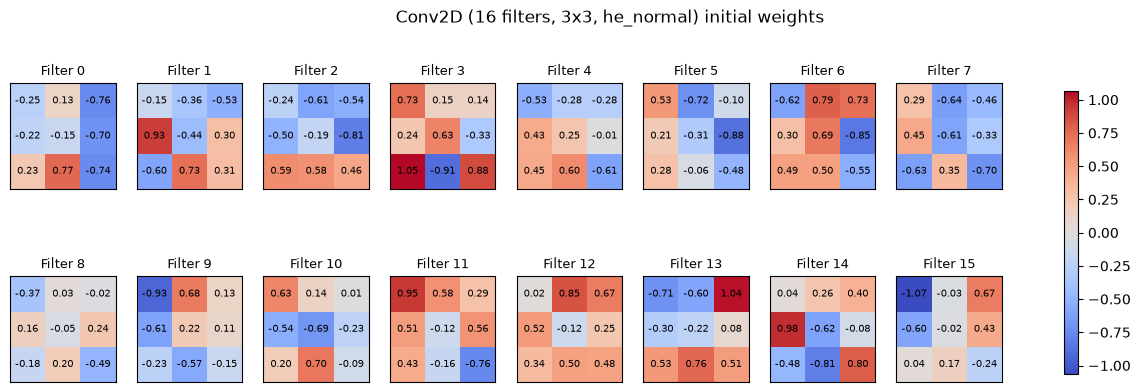

In [4]:
vmax = np.abs(weights).max()
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for i, ax in enumerate(axes.flat):
    f = weights[:, :, 0, i]
    im = ax.imshow(f, cmap="coolwarm", vmin=-vmax, vmax=vmax)
    for r in range(3):
        for c in range(3):
            ax.text(c, r, f"{f[r, c]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"Filter {i}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Conv2D (16 filters, 3x3, he_normal) initial weights")
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8)
save(fig, "section3_filter_weights.png")
plt.show()

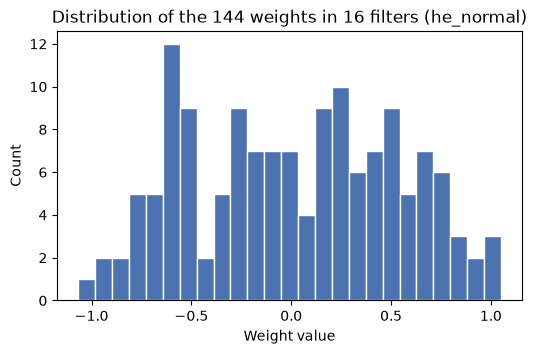

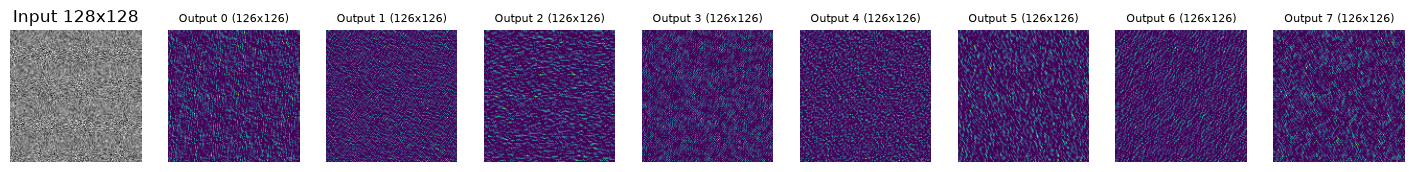

In [5]:
# Distribution of the weights and the feature maps produced on the random input
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(weights.ravel(), bins=25, color="#4C72B0", edgecolor="white")
ax.set_title("Distribution of the 144 weights in 16 filters (he_normal)")
ax.set_xlabel("Weight value"); ax.set_ylabel("Count")
save(fig, "section3_weight_histogram.png")
plt.show()

fig, axes = plt.subplots(1, 9, figsize=(18, 2.4))
axes[0].imshow(dummy_input[0, :, :, 0], cmap="gray"); axes[0].set_title("Input 128x128")
for i in range(8):
    axes[i + 1].imshow(output[0, :, :, i], cmap="viridis")
    axes[i + 1].set_title(f"Output {i} (126x126)", fontsize=8)
for ax in axes:
    ax.axis("off")
save(fig, "section3_feature_maps.png")
plt.show()

# Section 4: Examining the pooling operation

In [6]:
import tensorflow as tf

# Sample input matrix
input_data = tf.constant([
    [[1., 3., 2., 4.],
     [5., 6., 1., 2.],
     [7., 2., 8., 3.],
     [4., 1., 5., 9.]]
])

# Arrange dimensions: Batch, Height, Width, Channels
input_data = tf.reshape(input_data, (1, 4, 4, 1))

pool = tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=2
)

output = pool(input_data)

print("Input:")
print(input_data.numpy()[0, :, :, 0])

print("Pooling result:")
print(output.numpy()[0, :, :, 0])

Input:
[[1. 3. 2. 4.]
 [5. 6. 1. 2.]
 [7. 2. 8. 3.]
 [4. 1. 5. 9.]]
Pooling result:
[[6. 4.]
 [7. 9.]]


Manual calculation and comparison:

In [7]:
inp = input_data.numpy()[0, :, :, 0]
out = output.numpy()[0, :, :, 0]

manual = np.zeros((2, 2))
region_names = [["Top-left", "Top-right"], ["Bottom-left", "Bottom-right"]]
for i in range(2):
    for j in range(2):
        block = inp[2*i:2*i+2, 2*j:2*j+2]
        manual[i, j] = block.max()
        print(f"{region_names[i][j]:12s} region {block.ravel().tolist()} -> max = {block.max()}")

print("\nManually computed result:\n", manual)
print("Program result equals manual result?:", np.array_equal(manual, out))
print("Input tensor shape:", tuple(input_data.shape), "-> Output tensor shape:", tuple(output.shape))
print(f"Number of elements: {inp.size} -> {out.size} ({100 * (1 - out.size / inp.size):.0f}% reduction)")
print("Trainable parameters of the pooling layer:", pool.count_params())

Top-left     region [1.0, 3.0, 5.0, 6.0] -> max = 6.0
Top-right    region [2.0, 4.0, 1.0, 2.0] -> max = 4.0
Bottom-left  region [7.0, 2.0, 4.0, 1.0] -> max = 7.0
Bottom-right region [8.0, 3.0, 5.0, 9.0] -> max = 9.0

Manually computed result:
 [[6. 4.]
 [7. 9.]]
Program result equals manual result?: True
Input tensor shape: (1, 4, 4, 1) -> Output tensor shape: (1, 2, 2, 1)
Number of elements: 16 -> 4 (75% reduction)
Trainable parameters of the pooling layer: 0


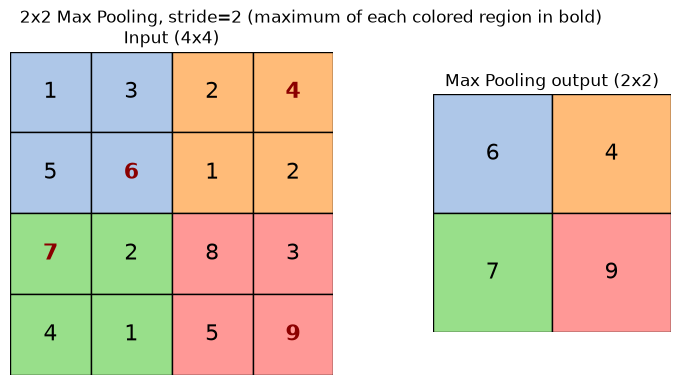

In [8]:
colors = np.array([[0, 0, 1, 1], [0, 0, 1, 1], [2, 2, 3, 3], [2, 2, 3, 3]])
palette = ["#AEC7E8", "#FFBB78", "#98DF8A", "#FF9896"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), gridspec_kw={"width_ratios": [2, 1.2]})
for ax, mat, title in [(axes[0], inp, "Input (4x4)"), (axes[1], out, "Max Pooling output (2x2)")]:
    n = mat.shape[0]
    for r in range(n):
        for c in range(n):
            color = palette[colors[r, c]] if n == 4 else palette[r * 2 + c]
            bold = n == 4 and mat[r, c] == out[r // 2, c // 2]
            ax.add_patch(plt.Rectangle((c, n - 1 - r), 1, 1, facecolor=color, edgecolor="black"))
            ax.text(c + 0.5, n - 0.5 - r, f"{mat[r, c]:.0f}", ha="center", va="center", fontsize=16,
                    fontweight="bold" if bold else "normal", color="darkred" if bold else "black")
    ax.set_xlim(0, n); ax.set_ylim(0, n); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title)
fig.suptitle("2x2 Max Pooling, stride=2 (maximum of each colored region in bold)")
save(fig, "section4_pooling.png")
plt.show()

# Section 5: Examining the ReLU and Softmax functions

In [9]:
import tensorflow as tf

x = tf.constant([-5., -2., -1., 0., 2., 4., 6.])

relu = tf.keras.layers.ReLU()
y = relu(x)
print("Input:", x.numpy())
print("ReLU output:", y.numpy())

Input: [-5. -2. -1.  0.  2.  4.  6.]
ReLU output: [0. 0. 0. 0. 2. 4. 6.]


In [10]:
tf.keras.utils.set_random_seed(0)
W1 = tf.random.normal((3, 4))
W2 = tf.random.normal((4, 2))
inputs = tf.random.normal((5, 3))

two_layers = (inputs @ W1) @ W2      # two layers without activation
one_layer = inputs @ (W1 @ W2)       # one combined layer
print("max |(x·W1)·W2 − x·(W1·W2)| =", float(tf.reduce_max(tf.abs(two_layers - one_layer))))

max |(x·W1)·W2 − x·(W1·W2)| = 4.76837158203125e-07


In [11]:
import tensorflow as tf

logits = tf.constant([[2.0, 1.0, 0.1]])
softmax = tf.keras.layers.Softmax()
probabilities = softmax(logits)
print("Softmax results:")
print(probabilities.numpy())
print("Sum of probabilities:")
print(tf.reduce_sum(probabilities).numpy())

Softmax results:
[[0.659  0.2424 0.0986]]
Sum of probabilities:
0.99999994


e^z = [7.389056 2.718282 1.105171]   sum = 11.2125
e^z / sum = [0.659001 0.242433 0.098566]
Class with the highest probability (argmax): 0


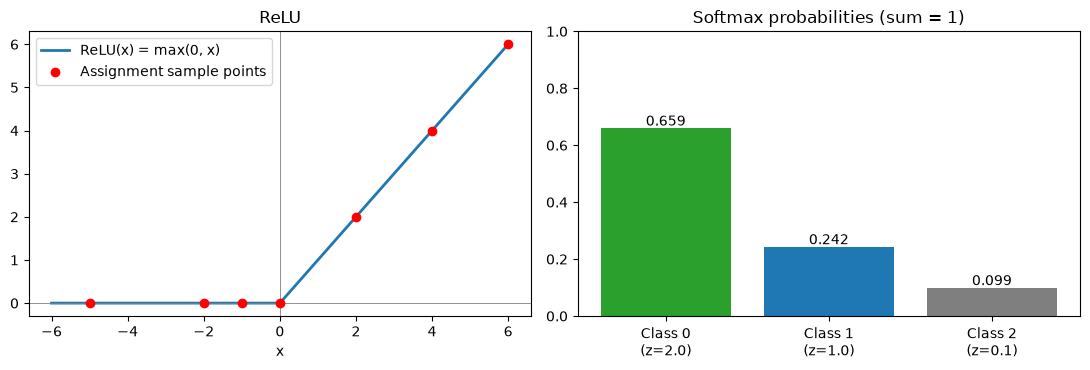

In [12]:
# Manual verification
np.set_printoptions(precision=6, suppress=True)
z = logits.numpy()[0]
e = np.exp(z)
print("e^z =", e, "  sum =", round(float(e.sum()), 4))
print("e^z / sum =", e / e.sum())
print("Class with the highest probability (argmax):", int(tf.argmax(probabilities, axis=1)[0]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
xs = np.linspace(-6, 6, 200)
axes[0].plot(xs, np.maximum(0, xs), lw=2, label="ReLU(x) = max(0, x)")
axes[0].scatter(x.numpy(), y.numpy(), color="red", zorder=3, label="Assignment sample points")
axes[0].axhline(0, color="gray", lw=0.6); axes[0].axvline(0, color="gray", lw=0.6)
axes[0].set_title("ReLU"); axes[0].legend(); axes[0].set_xlabel("x")
p = probabilities.numpy()[0]
bars = axes[1].bar(["Class 0\n(z=2.0)", "Class 1\n(z=1.0)", "Class 2\n(z=0.1)"], p,
                   color=["#2CA02C", "#1F77B4", "#7F7F7F"])
for b, v in zip(bars, p):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center")
axes[1].set_ylim(0, 1); axes[1].set_title("Softmax probabilities (sum = 1)")
fig.tight_layout()
save(fig, "section5_relu_softmax.png")
plt.show()

# Section 6: Building a simple CNN model

In [13]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)
# Normalization
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
# Add channel dimension
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]
print("Training data:", x_train.shape)
print("Test data:", x_test.shape)

Training data: (60000, 28, 28, 1)
Test data: (10000, 28, 28, 1)


Pixel range: 0.0 - 1.0
Training samples per class: [6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]


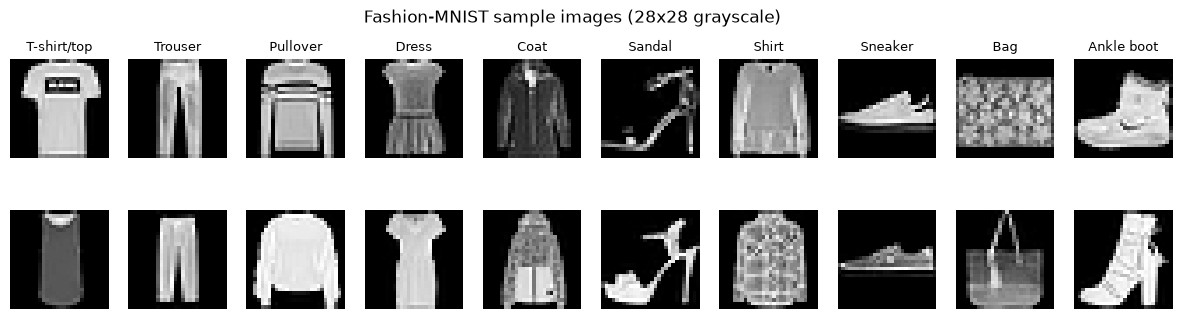

In [14]:
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Pixel range:", x_train.min(), "-", x_train.max())
print("Training samples per class:", np.bincount(y_train).tolist())

fig, axes = plt.subplots(2, 10, figsize=(15, 3.6))
for k in range(10):
    idx = np.where(y_train == k)[0][:2]
    for r in range(2):
        axes[r, k].imshow(x_train[idx[r], :, :, 0], cmap="gray")
        axes[r, k].axis("off")
    axes[0, k].set_title(CLASS_NAMES[k], fontsize=9)
fig.suptitle("Fashion-MNIST sample images (28x28 grayscale)")
save(fig, "section6_sample_images.png")
plt.show()

In [15]:
tf.keras.utils.set_random_seed(42)  # reproducible results

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    # First convolution
    tf.keras.layers.Conv2D(
        8, (3, 3),
        activation='relu'
    ),
    # First pooling
    tf.keras.layers.MaxPooling2D((2, 2)),
    # Second convolution
    tf.keras.layers.Conv2D(
        16, (3, 3),
        activation='relu'
    ),
    # Second pooling
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Convert multi-dimensional features to one dimension
    tf.keras.layers.Flatten(),
    # Fully connected layer
    tf.keras.layers.Dense(64, activation='relu'),
    # Output for 10 classes
    tf.keras.layers.Dense(10, activation='softmax')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        25,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,562 (107.66 KB)

 Trainable params: 27,562 (107.66 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

start = time.perf_counter()
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=2
)
training_time = time.perf_counter() - start

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print(f"Training time: {training_time:.1f} s")

Epoch 1/5
844/844 - 7s - 9ms/step - accuracy: 0.7694 - loss: 0.6287 - val_accuracy: 0.8195 - val_loss: 0.4812
Epoch 2/5
844/844 - 6s - 7ms/step - accuracy: 0.8471 - loss: 0.4232 - val_accuracy: 0.8457 - val_loss: 0.4248
Epoch 3/5
844/844 - 7s - 8ms/step - accuracy: 0.8641 - loss: 0.3764 - val_accuracy: 0.8587 - val_loss: 0.3881
Epoch 4/5
844/844 - 7s - 8ms/step - accuracy: 0.8752 - loss: 0.3461 - val_accuracy: 0.8665 - val_loss: 0.3595
Epoch 5/5
844/844 - 7s - 8ms/step - accuracy: 0.8816 - loss: 0.3242 - val_accuracy: 0.8735 - val_loss: 0.3417
Test Loss: 0.36316490173339844
Test Accuracy: 0.8690999746322632
Training time: 34.0 s


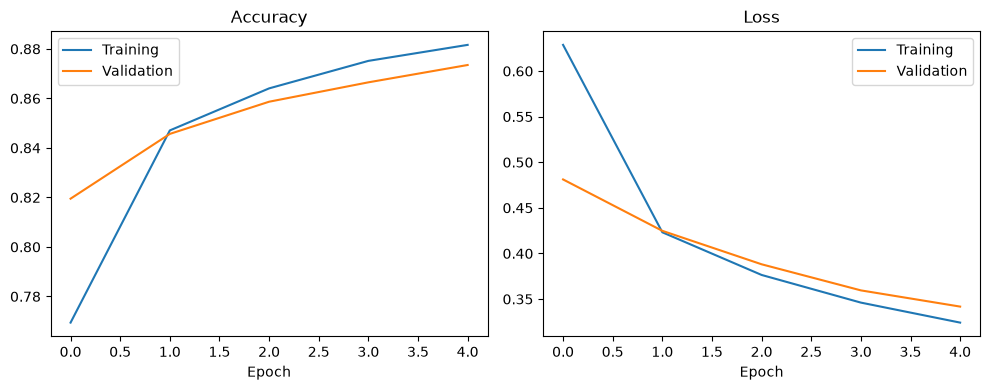

In [17]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
save(fig, "section6_training_curves.png")
plt.show()

Softmax output for the first test image:
  T-shirt/top  0.0000
  Trouser      0.0000
  Pullover     0.0000
  Dress        0.0000
  Coat         0.0000
  Sandal       0.0117
  Shirt        0.0000
  Sneaker      0.0935
  Bag          0.0004
  Ankle boot   0.8944
  Sum = 1.0000 | predicted = Ankle boot | true = Ankle boot

Per-class test accuracy:
  T-shirt/top  0.9150
  Trouser      0.9640
  Pullover     0.8500
  Dress        0.9140
  Coat         0.7860
  Sandal       0.9640
  Shirt        0.4510
  Sneaker      0.9730
  Bag          0.9650
  Ankle boot   0.9090


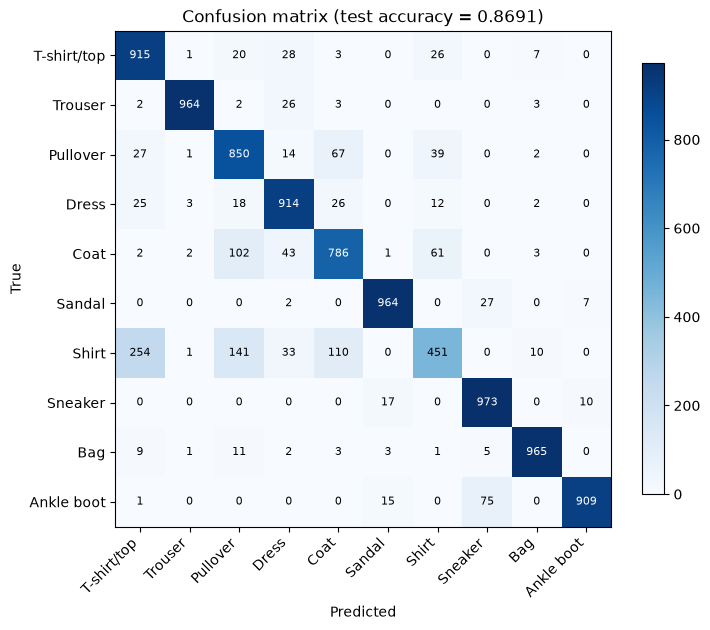

In [18]:
probs = model.predict(x_test, verbose=0)
y_pred = probs.argmax(axis=1)

print("Softmax output for the first test image:")
for k, p in enumerate(probs[0]):
    print(f"  {CLASS_NAMES[k]:12s} {p:.4f}")
print(f"  Sum = {probs[0].sum():.4f} | predicted = {CLASS_NAMES[y_pred[0]]} | true = {CLASS_NAMES[y_test[0]]}")

cm = tf.math.confusion_matrix(y_test, y_pred, num_classes=10).numpy()
print("\nPer-class test accuracy:")
for k in range(10):
    print(f"  {CLASS_NAMES[k]:12s} {cm[k, k] / cm[k].sum():.4f}")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Confusion matrix (test accuracy = {test_accuracy:.4f})")
fig.colorbar(im, shrink=0.8)
save(fig, "section6_confusion_matrix.png")
plt.show()

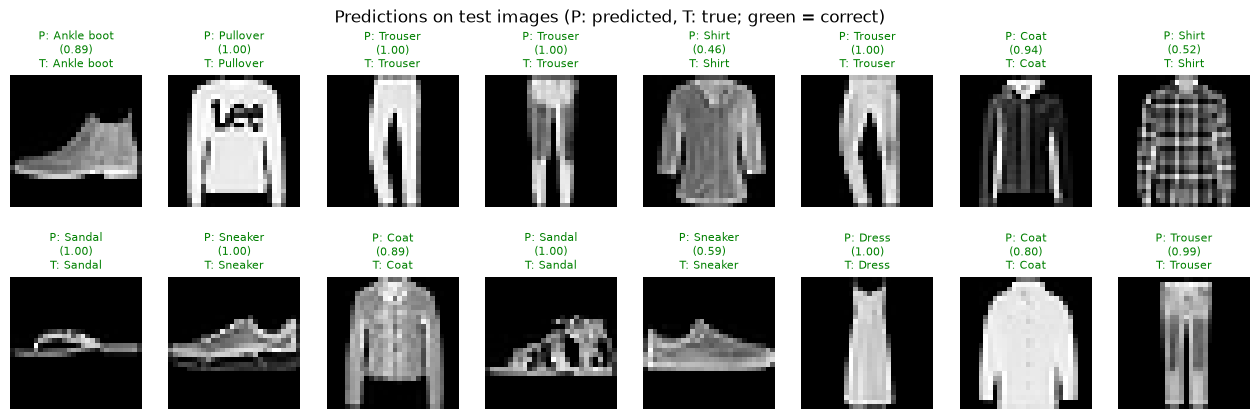

In [19]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i, :, :, 0], cmap="gray")
    correct = y_pred[i] == y_test[i]
    ax.set_title(f"P: {CLASS_NAMES[y_pred[i]]}\n({probs[i].max():.2f})\nT: {CLASS_NAMES[y_test[i]]}",
                 fontsize=8, color="green" if correct else "red")
    ax.axis("off")
fig.suptitle("Predictions on test images (P: predicted, T: true; green = correct)")
save(fig, "section6_sample_predictions.png")
plt.show()

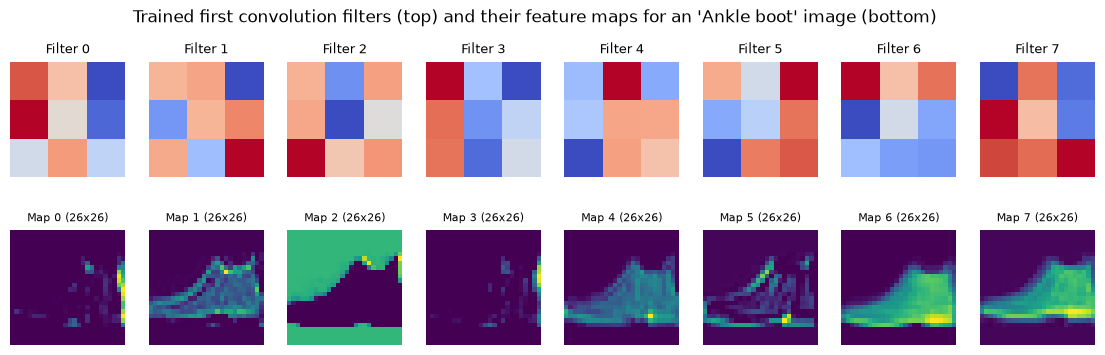

In [20]:
# Trained filters of the first convolution layer and their feature maps for one test image
w = model.layers[0].get_weights()[0]
intermediate = tf.keras.Model(model.inputs[0], model.layers[0].output)
fmap = intermediate(x_test[:1]).numpy()[0]

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    axes[0, i].imshow(w[:, :, 0, i], cmap="coolwarm"); axes[0, i].set_title(f"Filter {i}", fontsize=9)
    axes[1, i].imshow(fmap[:, :, i], cmap="viridis"); axes[1, i].set_title(f"Map {i} (26x26)", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle(f"Trained first convolution filters (top) and their feature maps for an "
             f"'{CLASS_NAMES[y_test[0]]}' image (bottom)")
save(fig, "section6_trained_filters.png")
plt.show()

# Section 7: Understanding the model architecture

In [21]:
print(f"{'Layer':18s} {'Type':13s} {'Output shape':22s} Params")
for layer in model.layers:
    print(f"{layer.name:18s} {layer.__class__.__name__:13s} {str(layer.output.shape):22s} {layer.count_params()}")

Layer              Type          Output shape           Params
conv2d_1           Conv2D        (None, 26, 26, 8)      80
max_pooling2d_1    MaxPooling2D  (None, 13, 13, 8)      0
conv2d_2           Conv2D        (None, 11, 11, 16)     1168
max_pooling2d_2    MaxPooling2D  (None, 5, 5, 16)       0
flatten            Flatten       (None, 400)            0
dense              Dense         (None, 64)             25664
dense_1            Dense         (None, 10)             650


# Section 8: A small experiment

In [22]:
def build_model(first_filters):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(first_filters, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(16, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])


def run_experiment(first_filters, verbose=2):
    tf.keras.utils.set_random_seed(42)          # identical starting conditions
    m = build_model(first_filters)
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    start = time.perf_counter()
    h = m.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=verbose)
    duration = time.perf_counter() - start
    loss, acc = m.evaluate(x_test, y_test, verbose=0)
    return {"filters": first_filters, "params": m.count_params(),
            "train_acc": h.history['accuracy'][-1], "val_acc": h.history['val_accuracy'][-1],
            "test_acc": acc, "test_loss": loss, "time": duration, "history": h.history}


print("Experiment 1: 8 filters")
exp1 = run_experiment(8)
print("\nExperiment 2: 16 filters")
exp2 = run_experiment(16)

Experiment 1: 8 filters
Epoch 1/5
844/844 - 6s - 7ms/step - accuracy: 0.7694 - loss: 0.6287 - val_accuracy: 0.8195 - val_loss: 0.4812
Epoch 2/5
844/844 - 4s - 5ms/step - accuracy: 0.8471 - loss: 0.4232 - val_accuracy: 0.8457 - val_loss: 0.4248
Epoch 3/5
844/844 - 4s - 5ms/step - accuracy: 0.8641 - loss: 0.3764 - val_accuracy: 0.8587 - val_loss: 0.3881
Epoch 4/5
844/844 - 4s - 5ms/step - accuracy: 0.8752 - loss: 0.3461 - val_accuracy: 0.8665 - val_loss: 0.3595
Epoch 5/5
844/844 - 5s - 5ms/step - accuracy: 0.8816 - loss: 0.3242 - val_accuracy: 0.8735 - val_loss: 0.3417

Experiment 2: 16 filters
Epoch 1/5
844/844 - 8s - 9ms/step - accuracy: 0.7806 - loss: 0.6117 - val_accuracy: 0.8327 - val_loss: 0.4712
Epoch 2/5
844/844 - 6s - 7ms/step - accuracy: 0.8539 - loss: 0.4029 - val_accuracy: 0.8597 - val_loss: 0.4027
Epoch 3/5
844/844 - 5s - 6ms/step - accuracy: 0.8712 - loss: 0.3554 - val_accuracy: 0.8718 - val_loss: 0.3640
Epoch 4/5
844/844 - 6s - 7ms/step - accuracy: 0.8805 - loss: 0.3279 - 

In [23]:
rows = [
    ("Number of filters", exp1["filters"], exp2["filters"]),
    ("Total parameters", exp1["params"], exp2["params"]),
    ("Training accuracy", f"{exp1['train_acc']:.4f}", f"{exp2['train_acc']:.4f}"),
    ("Validation accuracy", f"{exp1['val_acc']:.4f}", f"{exp2['val_acc']:.4f}"),
    ("Test accuracy", f"{exp1['test_acc']:.4f}", f"{exp2['test_acc']:.4f}"),
    ("Test loss", f"{exp1['test_loss']:.4f}", f"{exp2['test_loss']:.4f}"),
    ("Training time", f"{exp1['time']:.1f} s", f"{exp2['time']:.1f} s"),
]
print(f"| {'Metric':20s} | {'Experiment 1':>12s} | {'Experiment 2':>12s} |")
print(f"|{'-'*22}|{'-'*14}|{'-'*14}|")
for name, a, b in rows:
    print(f"| {name:20s} | {str(a):>12s} | {str(b):>12s} |")

| Metric               | Experiment 1 | Experiment 2 |
|----------------------|--------------|--------------|
| Number of filters    |            8 |           16 |
| Total parameters     |        27562 |        28794 |
| Training accuracy    |       0.8816 |       0.8872 |
| Validation accuracy  |       0.8735 |       0.8788 |
| Test accuracy        |       0.8691 |       0.8744 |
| Test loss            |       0.3632 |       0.3543 |
| Training time        |       22.8 s |       31.2 s |


FileNotFoundError: [Errno 2] No such file or directory: 'outputs/section8_comparison.png'

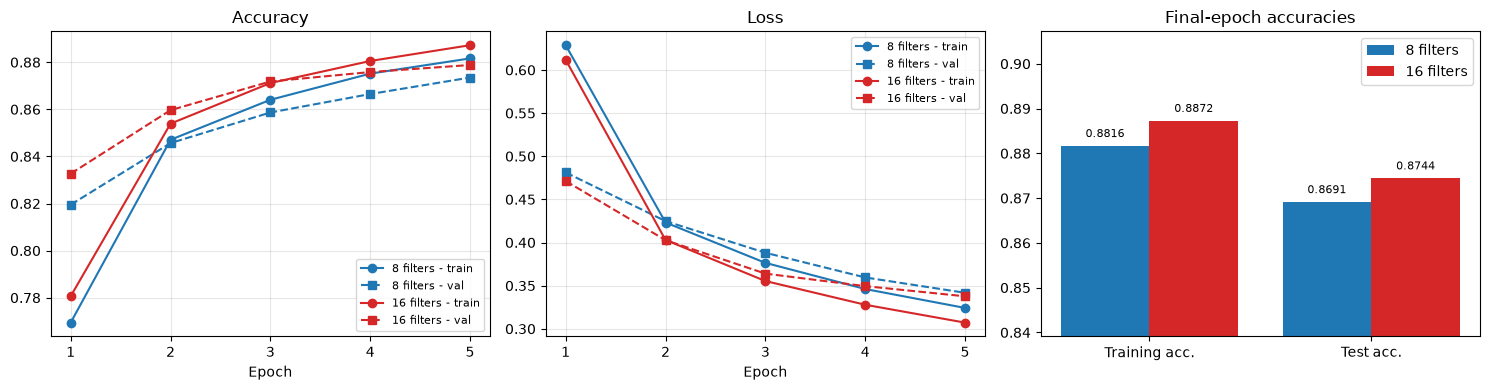

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ep = range(1, 6)
for name, r, c in [("8 filters", exp1, "#1F77B4"), ("16 filters", exp2, "#D62728")]:
    axes[0].plot(ep, r["history"]["accuracy"], "o-", color=c, label=f"{name} - train")
    axes[0].plot(ep, r["history"]["val_accuracy"], "s--", color=c, label=f"{name} - val")
    axes[1].plot(ep, r["history"]["loss"], "o-", color=c, label=f"{name} - train")
    axes[1].plot(ep, r["history"]["val_loss"], "s--", color=c, label=f"{name} - val")
axes[0].set_title("Accuracy"); axes[1].set_title("Loss")
for ax in axes[:2]:
    ax.set_xticks(ep); ax.set_xlabel("Epoch"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
v1 = [exp1["train_acc"], exp1["test_acc"]]; v2 = [exp2["train_acc"], exp2["test_acc"]]
xpos = np.arange(2)
b1 = axes[2].bar(xpos - 0.2, v1, 0.4, label="8 filters", color="#1F77B4")
b2 = axes[2].bar(xpos + 0.2, v2, 0.4, label="16 filters", color="#D62728")
for b, v in list(zip(b1, v1)) + list(zip(b2, v2)):
    axes[2].text(b.get_x() + b.get_width() / 2, v + 0.002, f"{v:.4f}", ha="center", fontsize=8)
axes[2].set_xticks(xpos); axes[2].set_xticklabels(["Training acc.", "Test acc."])
axes[2].set_ylim(min(v1 + v2) - 0.03, max(v1 + v2) + 0.02)
axes[2].legend(); axes[2].set_title("Final-epoch accuracies")
fig.tight_layout()
save(fig, "section8_comparison.png")
plt.show()

Filters | Params | Train acc | Test acc |    Time
      4 |  26946 |    0.8784 |   0.8666 |    9.1s
      8 |  27562 |    0.8816 |   0.8691 |    9.8s
     16 |  28794 |    0.8872 |   0.8744 |   13.1s
     32 |  31258 |    0.8888 |   0.8688 |   20.6s
     64 |  36186 |    0.8939 |   0.8784 |   37.3s


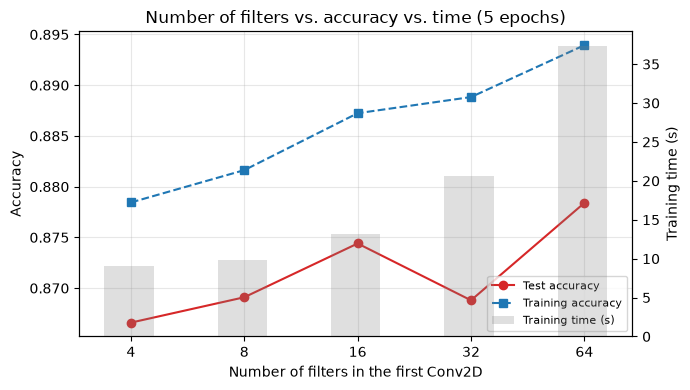

In [ ]:
extra = {8: exp1, 16: exp2}
for f in [4, 32, 64]:
    extra[f] = run_experiment(f, verbose=0)

fs = sorted(extra)
print(f"{'Filters':>7s} | {'Params':>6s} | {'Train acc':>9s} | {'Test acc':>8s} | {'Time':>7s}")
for f in fs:
    r = extra[f]
    print(f"{f:7d} | {r['params']:6d} | {r['train_acc']:9.4f} | {r['test_acc']:8.4f} | {r['time']:6.1f}s")

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(fs, [extra[f]["test_acc"] for f in fs], "o-", color="#D62728", label="Test accuracy")
ax1.plot(fs, [extra[f]["train_acc"] for f in fs], "s--", color="#1F77B4", label="Training accuracy")
ax1.set_xscale("log", base=2); ax1.set_xticks(fs); ax1.set_xticklabels(fs)
ax1.set_xlabel("Number of filters in the first Conv2D"); ax1.set_ylabel("Accuracy"); ax1.grid(alpha=0.3)
ax2 = ax1.twinx()
ax2.bar(fs, [extra[f]["time"] for f in fs], width=[f * 0.3 for f in fs], alpha=0.25, color="gray",
        label="Training time (s)")
ax2.set_ylabel("Training time (s)")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=8)
ax1.set_title("Number of filters vs. accuracy vs. time (5 epochs)")
fig.tight_layout()
save(fig, "section8_extra_experiment.png")
plt.show()